# PSA のエネルギーの較正: ピクセルごとの p0, p1(`energy_haNN.csv`)

`PSA_Calibration` は、ピクセルごとの係数で **`energy = p0 + p1 × hg_corr`** [keV] にします(`hg_corr` は温度で直した hg)。
係数の表 `calib/psa/energy_haNN.csv`(`ch,n,m,p0,p1`)を、Cs-137 と Co-60 のランから作るのが `scripts/calib/make_psa_energy.py` です。
fit のしかたは `analysis_sm3_FM/PSA_analysis/src_onoda/energy_calib.py`(Notion の「analysis_sm3_FM のコードの解説」)と同じで、それを ch ごとからピクセルごとにしました。

| 手順 | 中身 |
|---|---|
| 0. 準備 | 位置(`position_haNN.csv`)と温度ゲイン(`temp_gain_haNN.csv`)を `calib/psa` に置いた状態で、線源のランをチェーンに通す(ピクセルと `hg_corr` が要る) |
| 1. ヒットを選ぶ | ピクセルがあり、飽和していなく、ピークがトリガーの時刻のもの。さらに、温度 `temp_mean` がその ch の温度ゲインの表の範囲の中のもの(外では表の端の値のままなので、1 °C で約 8 % ずれる) |
| 2. Cs 662 keV | ガウス + 直線の背景。窓は、なめらかにしたスペクトルの最大の 0.8〜1.25 倍(energy_calib.py の「中心 − 1σ 〜 + 2σ」は、ピクセルの統計ではガウスと背景の区別がつかず fit が暴れるので広くした) |
| 3. Co 1173 / 1332 keV | 2 本は分かれず 1 つの山になる。ガウス 2 本 + 直線の背景で、1332 keV の中心は 1173 keV の r 倍(r = 1.06〜1.16)、幅は √r 倍、高さの比 0.5〜1.5(energy_calib.py と同じ) |
| 4. 係数 | 3 点に `hg_corr = a E + b` を当てはめ、`p1 = 1/a`、`p0 = −b/a`(`src` = `pixel`) |
| 5. Co が使えないピクセル | ヒットが `--min-hits`(1000)未満、fit の失敗、1173/662 の比が 1.55〜1.95 の外、p1 の誤差が 3 % 超: その ch の和の `p0` と、ピクセルの Cs の位置から `p1`(`src` = `cs+ch`)。Cs も無いピクセルは ch の和の係数(`src` = `ch`) |

`--co` を付けなければ、Cs の 1 本で `p0 = 0` の較正になります(前の作り方)。

In [ ]:
# ===== 入力と出力(絶対パス。データ量が大きいので、リポジトリの外の NAS などに置く)=====
from pathlib import Path
# 入力: UVSOR2026_late(killua/<ラン>, calltt/<ラン> があるディレクトリ)
DATA = Path("/mnt/d/UVSOR2026_late")
# 出力: チェーンの出力の置き場(チュートリアル間で共有)
CACHE = Path("/mnt/nas_eureka/onoda/<書き換え>/EricaNext_tutorial")
# 出力: このノートブックで作る較正ファイル(calib/psa は上書きしない)
CAL_OUT = CACHE / "calib_psa"

for p in (DATA, CACHE):
    if "<" in str(p):
        raise ValueError(f"パスを書き換えてください: {p}")
CAL_OUT.mkdir(parents=True, exist_ok=True)
print("入力:", DATA)
print("出力:", CACHE)
print("較正ファイル:", CAL_OUT)


In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import Image, display
import ROOT
ROOT.gROOT.SetBatch(True)

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
CALIB_SCRIPTS = REPO / "scripts" / "calib"
sys.path.insert(0, str(CALIB_SCRIPTS))
PYTHON = "/usr/bin/python3"                # scripts/calib を動かす Python(numpy, scipy, PyROOT)

def run(cmd, show=True):
    """コマンドを実行し、出力を表示する"""
    print(" ".join(str(c) for c in cmd))
    r = subprocess.run([str(c) for c in cmd], capture_output=True, text=True)
    if show:
        print(r.stdout[-4000:])
    if r.returncode != 0:
        print(r.stderr[-4000:])
    r.check_returncode()

def chain(run_name, out, *args):
    """UVSOR のラン 1 本を smile3_psa で流す(出力が既にあれば何もしない)"""
    if out.exists():
        return out
    run([sys.executable, RUN_CHAIN, "smile3_psa", "-o", out, "--data-dir", DATA / "killua" / run_name,
         "--set", "PSA_ReadData.extra_data_dirs=" + json.dumps([str(DATA / "calltt" / run_name)]), *args], show=False)
    return out

## 1. データ

2026-11-03 の UVSOR での HA_cal のランを使います(解析用の計算機の D ドライブ `/mnt/d/UVSOR2026_late`。
ほかの場所にあるときは冒頭の `DATA` を書き換える)。ランの記録は Notion の
「SMILE-3 FM UVSOR 試験(2026-11-03)データ確認と HA_cal の解析」にあります。

| ラン | 線源 | 温度 | 中身 |
|---|---|---|---|
| run01〜11 | Cs-137 | 39〜49 °C | 1 ランは約 2 分。多くは storage の OOM で途中で止まった(.dat.tmp が残る) |
| run12 | Co-60 | 47〜50 °C | 4 時間。ha02 で 1 ch あたり 130〜160 万ヒット。ほぼ全部がトリガーの時刻に入る。ha04 は無い |

チェーンの出力は 1 ランに 1 つ、`<CACHE>/psa_<ラン>.root`(`CACHE` は冒頭で指定)に置き、既にあれば流し直しません
(Cs は 1 ランに 1〜4 分、run12 は約 2 時間)。

## 2. 位置と温度ゲインを置いた状態で Cs と Co のランを流す

`calib/psa` の位置と温度ゲインを使って流した出力は、`psa_cal_<ラン>.root` という名前にします(温度ゲインの表を作るのに使った `psa_<ラン>.root` とは別)。
run12 は `part0`〜`part4` のサブディレクトリに分かれているので `PSA_ReadData.recursive=true` を付けます(約 2 時間)。

In [2]:
print("calib/psa:", sorted(p.name for p in (REPO / "calib" / "psa").glob("temp_gain_ha*.csv"))[:3], "...")
CS_ROOTS = [chain(r, CACHE / f"psa_cal_{r}.root") for r in [f"20261103_run{k:02d}" for k in range(1, 12)]]
CO_ROOTS = [chain("20261103_run12", CACHE / "psa_cal_20261103_run12.root", "--set", "PSA_ReadData.recursive=true")]
print(len(CS_ROOTS), "Cs files,", len(CO_ROOTS), "Co file")

calib/psa: ['temp_gain_ha00.csv', 'temp_gain_ha01.csv', 'temp_gain_ha02.csv'] ...
11 Cs files, 1 Co file


Co のランの温度は 47〜50 °C で、温度ゲインの表(Cs のラン、多くのボードで 47.5 °C まで)の端を少し越えます。
表の範囲の中だけを使うので、Co のヒットは一部しか使いません(ha02 で約 3 割)。

In [3]:
from psa_calib_common import read_tree
t = read_tree([str(CO_ROOTS[0])], ["temp_mean"], "board == 2 && pixel >= 0")["temp_mean"]
print("ha02 run12 temp_mean 5/50/95 %:", np.percentile(t, [5, 50, 95]).round(2))
from make_psa_energy import temp_ranges
print("ha02 temperature ranges of the temp_gain table (used for the hits):", {c: r for c, r in temp_ranges(str(REPO / "calib" / "psa"), 2).items()})
print("ha02 run12 hits inside the ch0 range:", f"{np.mean(t <= temp_ranges(str(REPO / 'calib' / 'psa'), 2)[0][1]):.0%}")

ha02 run12 temp_mean 5/50/95 %: [47.63 48.14 48.44]
ha02 temperature ranges of the temp_gain table (used for the hits): {0: (39.0, 48.0), 1: (39.0, 48.0), 2: (39.0, 48.0), 3: (39.0, 48.0), 4: (39.0, 48.0), 5: (39.0, 48.0)}
ha02 run12 hits inside the ch0 range: 31%


## 3. 係数を作る

ha02 を作ります(全ボードなら `--boards` を外す)。

In [4]:
run([PYTHON, CALIB_SCRIPTS / "make_psa_energy.py", "-o", CAL_OUT, "--boards", "2",
     "--cs", *CS_ROOTS, "--co", *CO_ROOTS, "--overwrite"])
print("".join(l for l in open(CAL_OUT / "energy_ha02.csv").readlines()[:30] if not l.startswith("# input")))

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/scripts/calib/make_psa_energy.py -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/calib_psa --boards 2 --cs /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run01.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run02.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run03.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run04.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run05.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run06.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run07.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run08.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run09.root /home/onoda/ANLNext/Erica

ha02: /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/calib_psa/energy_ha02.csv (384 pixels: pixel 363, cs+ch 21, ch 0; quality bad: 0)

# made by scripts/calib/make_psa_energy.py, 2026-11-07T01:37:13
# hits: !satu_h && !satu_l && pixel >= 0 && (board == 2), at the trigger time (peak_id 27-29 Cs, 26-29 Co), temp_mean inside the temperature gain table of the ch (/home/onoda/ANLNext/Erica_git_dev/EricaNext/calib/psa)
# spectra of hg_corr (600 bins up to 150000); Cs 661.66 keV: psa_cal_20261103_run01.root, psa_cal_20261103_run02.root, psa_cal_20261103_run03.root, psa_cal_20261103_run04.root, psa_cal_20261103_run05.root, psa_cal_20261103_run06.root, psa_cal_20261103_run07.root, psa_cal_20261103_run08.root, psa_cal_20261103_run09.root, psa_cal_20261103_run10.root, psa_cal_20261103_run11.root; Co 1173.23, 1332.49 keV: psa_cal_20261103_run12.root
# E = p0 + p1 hg_corr from the 3 lines (src pixel), from the pixel's Cs line and p0 of the ch sum (cs+ch), or of the ch sum (ch)
# ch su

## 4. 確認

`qa/energy_ha02.png` の上から: ch の和のスペクトル(赤線が fit した線の位置)、ch の和の直線(残差は keV)、ピクセルごとの `p1`、`p0`
(`c` は Co が使えず `cs+ch` にしたピクセル)。隣のピクセルと大きく違う所は、線の位置を取り違えている可能性があります。

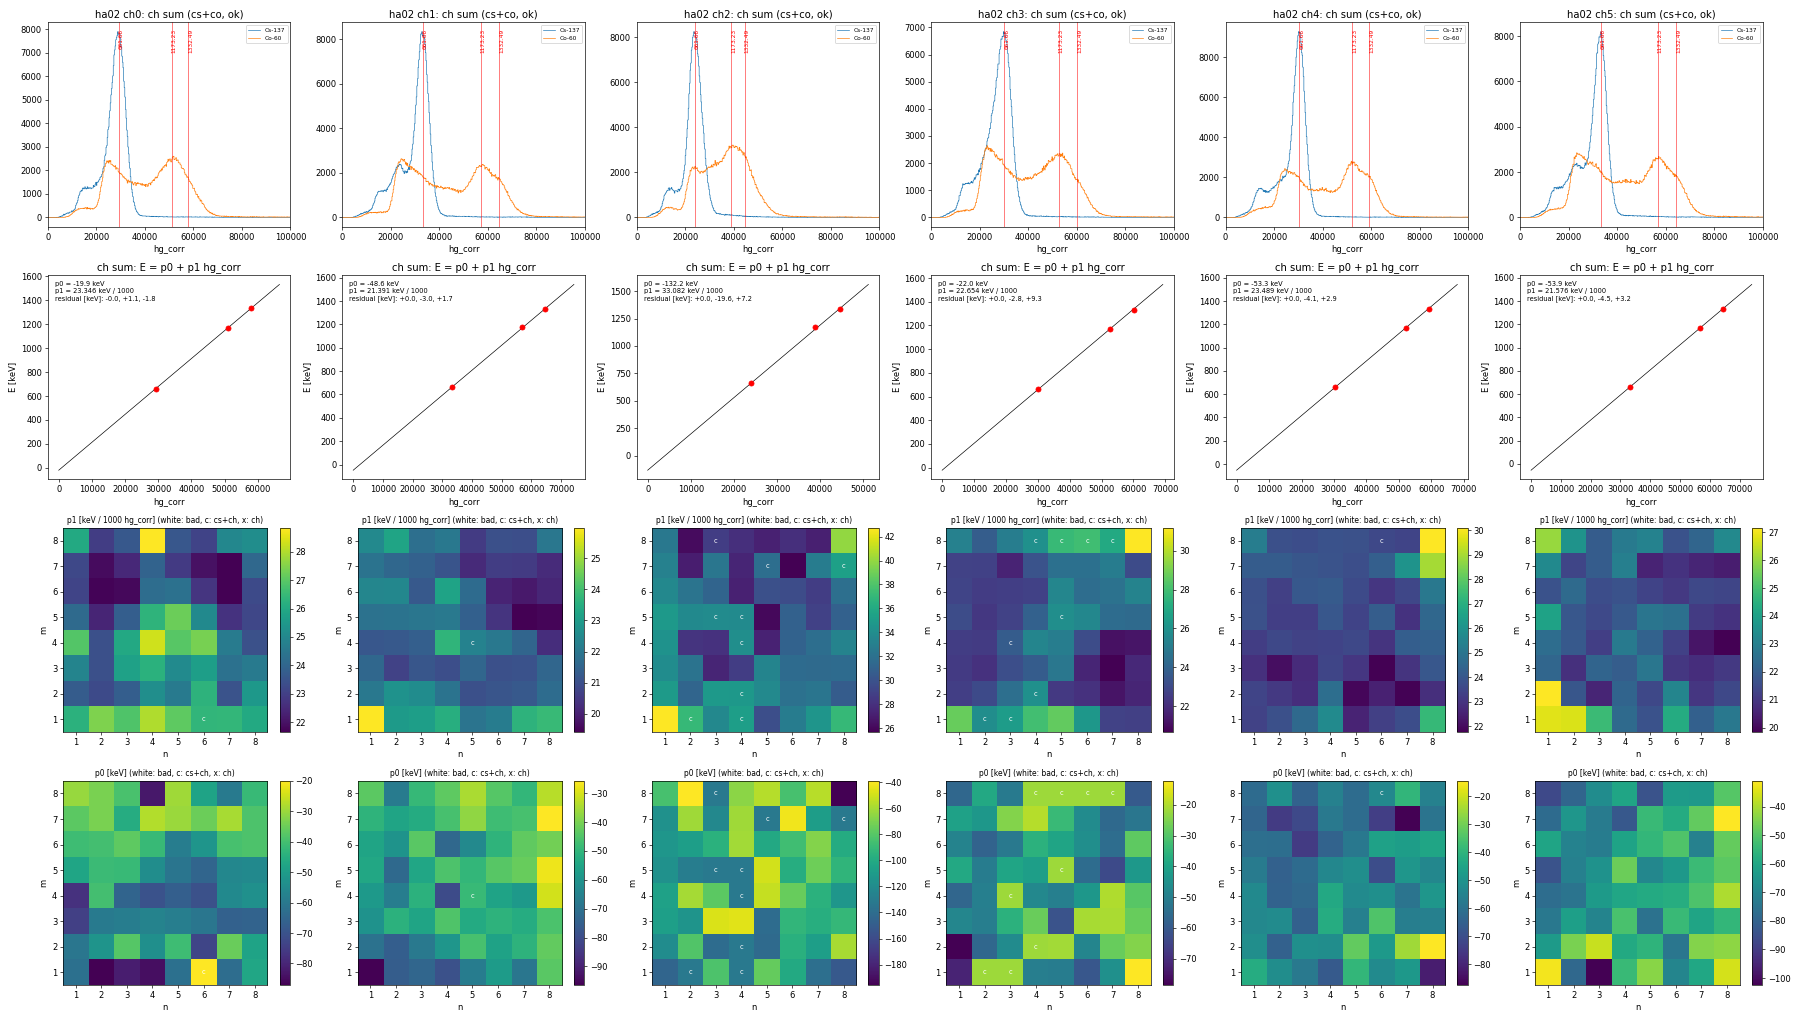

In [5]:
display(Image(filename=str(CAL_OUT / "qa" / "energy_ha02.png")))

作った係数で、ピクセルごとにエネルギーに直したスペクトルを、ch ごとに足して描きます(左 Cs、右 Co。温度ゲインの表の範囲の中のヒット)。
662、1173、1332 keV にそろえば、ピクセルごとのゲインの違いと直線からのずれが直っています。

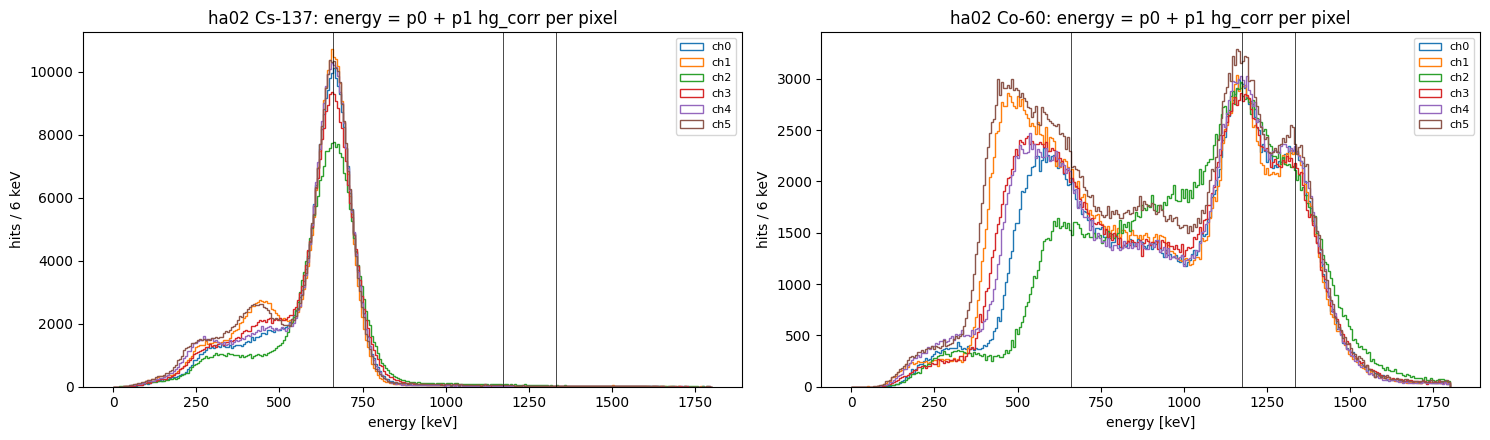

In [6]:
import csv
from make_psa_energy import temp_ranges
rows = list(csv.DictReader(l for l in open(CAL_OUT / "energy_ha02.csv") if not l.startswith("#")))
coef = {(int(r["ch"]), int(r["n"]), int(r["m"])): (float(r["p0"]), float(r["p1"])) for r in rows}
tr = temp_ranges(str(REPO / "calib" / "psa"), 2)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, roots, name in ((axs[0], CS_ROOTS, "Cs-137"), (axs[1], CO_ROOTS, "Co-60")):
    d = read_tree([str(r) for r in roots], ["ch", "pix_n", "pix_m", "hg_corr", "temp_mean"],
                  "board == 2 && pixel >= 0 && !satu_h && !satu_l && peak_id >= 26 && peak_id <= 29")
    k = np.array([coef.get((c, n, m), (np.nan, np.nan)) for c, n, m in zip(d["ch"], d["pix_n"], d["pix_m"])])
    e = k[:, 0] + k[:, 1] * d["hg_corr"]
    for c in range(6):
        s = (d["ch"] == c) & (d["temp_mean"] >= tr[c][0]) & (d["temp_mean"] <= tr[c][1])
        ax.hist(e[s], bins=300, range=(0, 1800), histtype="step", label=f"ch{c}")
    for E in (661.66, 1173.23, 1332.49):
        ax.axvline(E, color="k", lw=0.5)
    ax.set_xlabel("energy [keV]"); ax.set_ylabel("hits / 6 keV"); ax.set_title(f"ha02 {name}: energy = p0 + p1 hg_corr per pixel")
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 5. 使う

確認して使えると判断したら、`calib/psa/` に書きます。次にチェーンを流すと、`energy` と `PSA_Calibration/Energy_haNN` が入ります。

```bash
/usr/bin/python3 scripts/calib/make_psa_energy.py -o calib/psa --overwrite     --cs <CACHE>/psa_cal_20261103_run{01..11}.root --co <CACHE>/psa_cal_20261103_run12.root
```